In [23]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import seaborn as sns

In [24]:
df=pd.read_csv("Mall_Customers.csv")


In [25]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values per column:")
print(df.nunique())


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values: 0

Duplicate rows: 0

Unique values per column:
CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64


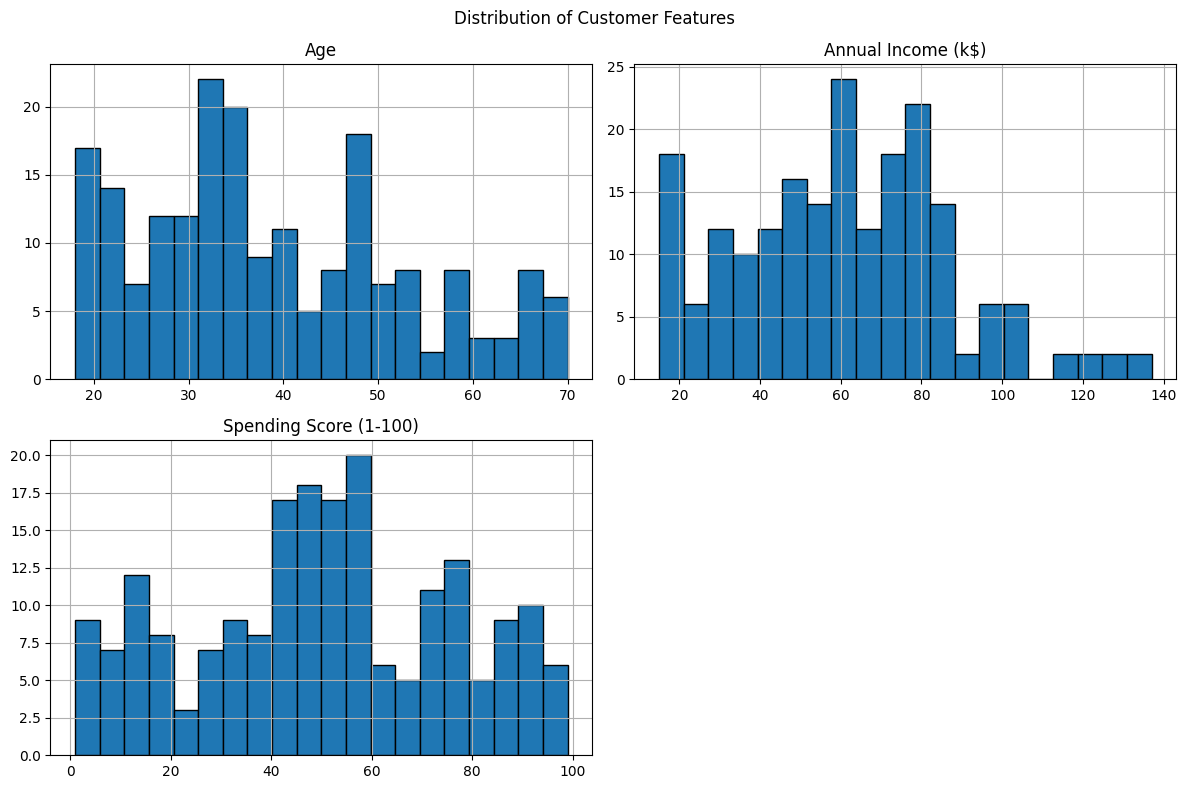

In [26]:
# 5. HISTOGRAMS
# ==========================================
numeric_cols = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

df[numeric_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Customer Features")
plt.tight_layout()
plt.show()

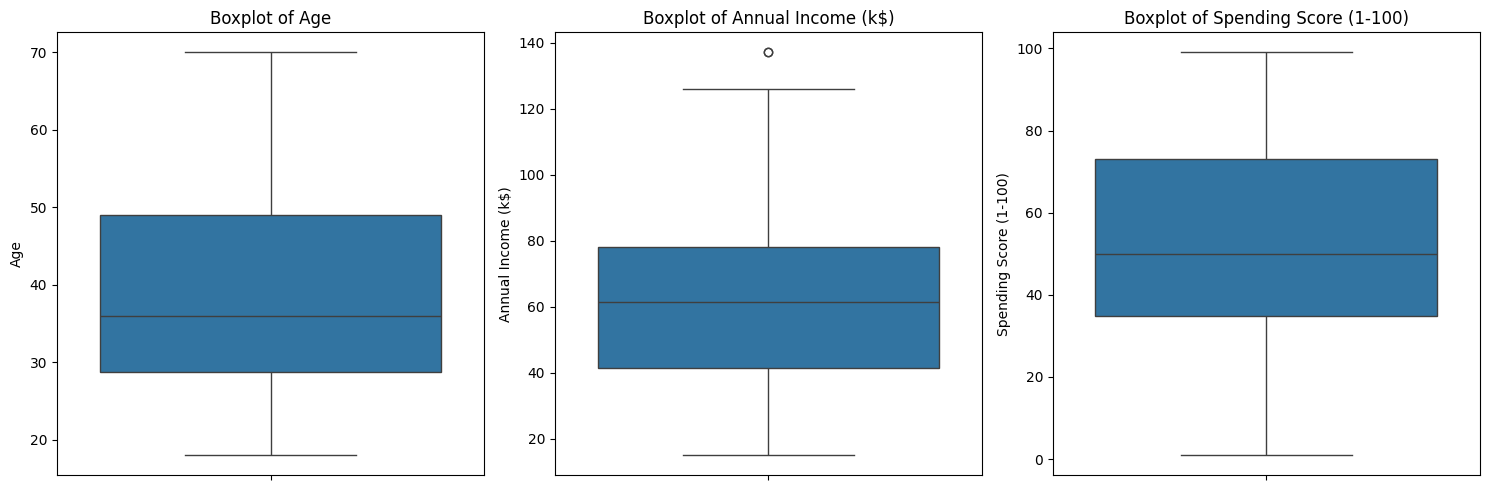

In [27]:
# 6. BOXPLOTS: OUTLIER EXPLORATION
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

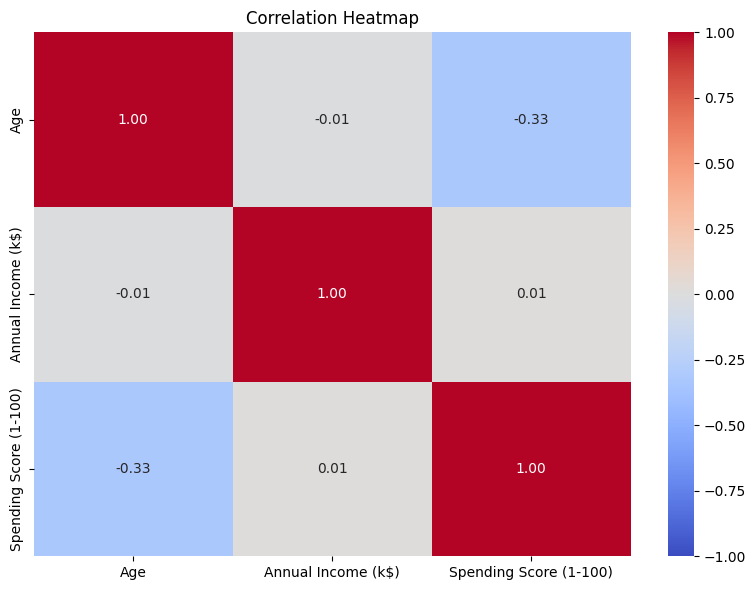

In [28]:
# 8. CORRELATION HEATMAP
# Exclude CustomerID because it is an identifier
# ==========================================
corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [29]:
X = df[[
    
    "Annual Income (k$)",
    "Spending Score (1-100)"
]]


In [30]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

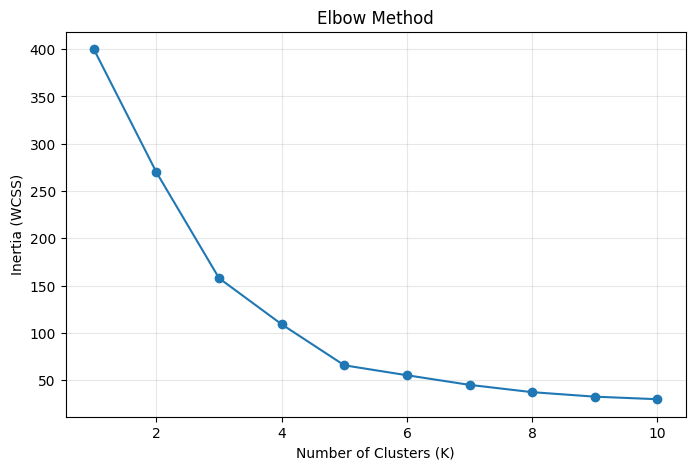

In [31]:
#  Find the best K using the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
# 5. Train final K-Means model
kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    random_state=42,
    n_init=20,
    max_iter=500
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

In [33]:
# 6. Evaluate clustering
score = silhouette_score(X_scaled, df["Cluster"])

print("Number of customers:", len(df))
print("Number of clusters:", df["Cluster"].nunique())
print("Inertia:", round(kmeans.inertia_, 3))
print("Silhouette Score:", round(score, 3))
print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

Number of customers: 200
Number of clusters: 5
Inertia: 65.568
Silhouette Score: 0.555

Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [34]:
# 7. Get centroids in original units
centers = scaler.inverse_transform(kmeans.cluster_centers_)

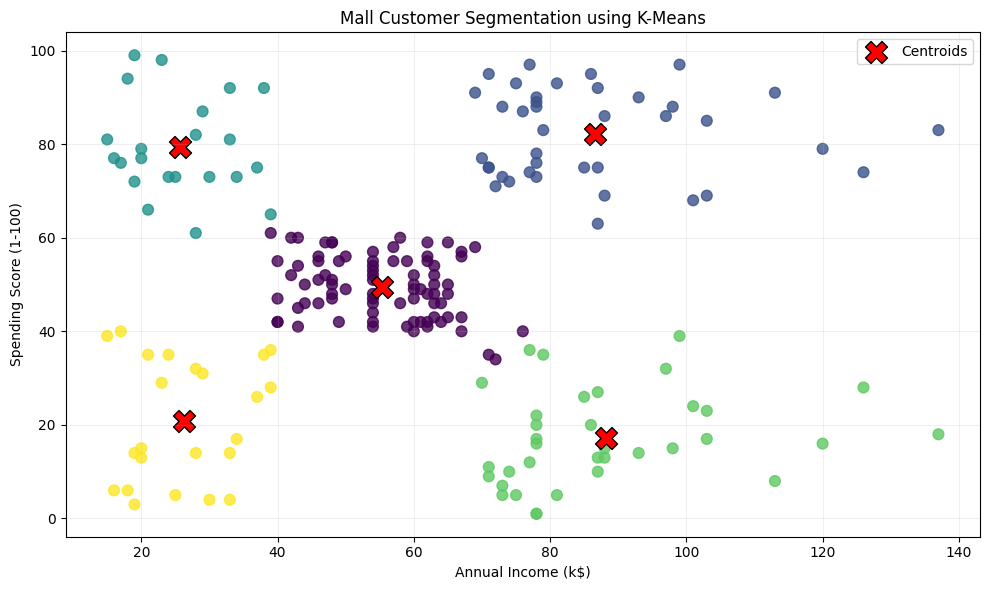


Results saved successfully!


In [35]:
# 8. Plot customer clusters

plt.figure(figsize=(10, 6))

plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segmentation using K-Means")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# 9. Save results
df.to_csv("Mall_Customers_KMeans_Groups.csv", index=False)

print("\nResults saved successfully!")

In [36]:
# 9. Save results
df.to_csv("Mall_Customers_KMeans_Groups.csv", index=False)

print("\nResults saved successfully!")


Results saved successfully!


# for prediction

In [37]:

# Predict cluster for a new customer

income = 80
spending_score = 75

# Create input DataFrame
new_customer = pd.DataFrame({
    "Annual Income (k$)": [income],
    "Spending Score (1-100)": [spending_score]
})

# Scale using the existing scaler
new_customer_scaled = scaler.transform(new_customer)

# Predict cluster
predicted_cluster = kmeans.predict(new_customer_scaled)[0]

print("Annual Income:", income, "thousand dollars")
print("Spending Score:", spending_score)
print("Predicted Cluster:", predicted_cluster)


Annual Income: 80 thousand dollars
Spending Score: 75
Predicted Cluster: 1


In [38]:
income = float(input("Enter annual income (in $1000s): "))
spending_score = float(input("Enter spending score (1-100): "))

if not 1 <= spending_score <= 100:
    raise ValueError("Spending score must be between 1 and 100.")

new_customer = pd.DataFrame({
    "Annual Income (k$)": [income],
    "Spending Score (1-100)": [spending_score]
})

scaled_input = scaler.transform(new_customer)
cluster = kmeans.predict(scaled_input)[0]

print("Predicted customer cluster:", cluster)

Enter annual income (in $1000s):  exit


ValueError: could not convert string to float: 'exit'